# 03 · Modelo preditivo de NPS

**Tech Challenge Fase 1 · NPS Preditivo (desafio 4, opcional)**

Hoje o NPS só é conhecido depois que a jornada termina, quando já não dá para fazer nada pelo
cliente. A proposta deste notebook é **estimar a nota de cada pedido antes da pesquisa**, usando
apenas o que a operação já sabe, para que a empresa aja enquanto ainda dá tempo.

Roteiro (segue os itens pedidos no desafio):

1. a pergunta que o modelo responde;
2. a estratégia: regressão ou classificação?;
3. a definição da variável alvo;
4. a seleção das variáveis de entrada;
5. a preparação das variáveis;
6. a lógica de separação dos dados;
7. a escolha do modelo;
8. a avaliação dos resultados;
9. o que o modelo aprendeu;
10. a simulação de cenários;
11. como a empresa usaria o modelo na prática;
12. as limitações e os riscos.

As funções estão em [`src/modeling.py`](../src/modeling.py). O mesmo pipeline roda fora do
notebook com `python -m src.train_model` e `python -m src.predict`.

In [1]:
import sys
from pathlib import Path

# Localiza a raiz do projeto (a pasta que contém src/) para importar o código compartilhado,
# não importa de onde o notebook seja aberto.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "config.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src import config, data_prep, modeling
from src import visualization as viz
from src.predict import score_orders

viz.apply_style()
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")
pd.set_option("display.max_colwidth", 120)

df = data_prep.load_processed_data()

## 1. A pergunta que o modelo responde

> **"Assim que o pedido é entregue, e antes de enviarmos a pesquisa, qual nota esse cliente tende
> a dar? Quem precisa de uma ação agora, e por quê?"**

O modelo não substitui a pesquisa de NPS. Ele cria uma **nota prevista** para todos os pedidos,
inclusive os de clientes que nunca respondem pesquisa, e transforma essa nota em uma **fila de ação**.

## 2. Estratégia: regressão ou classificação?

| | Regressão | Classificação |
|---|---|---|
| O que prevê | A nota de 0 a 10 | Uma categoria (ex.: detrator ou não) |
| Vantagem técnica | Usa toda a informação da nota (6,9 é diferente de 0,0) | Foca direto na decisão "agir / não agir" |
| Desvantagem técnica | Tende a "puxar" as previsões para a média | Junta notas muito diferentes na mesma classe; aqui as classes são desbalanceadas (84% detratores) |
| Linguagem para o negócio | "A nota prevista é 3,2" e "cada dia de atraso custa 0,9 ponto" | "Probabilidade de 92% de ser detrator" |

**Decisão: regressão como modelo principal, com a classificação como comparação.**

- **Por que regressão (técnico):** a nota da base é contínua (101 valores distintos, com casa
  decimal). Transformá-la em "detrator sim/não" jogaria fora a diferença entre um cliente furioso
  (nota 0) e um quase satisfeito (nota 6,9). Além disso, ordenar os pedidos pela nota prevista já
  resolve a tarefa da classificação. Isso é verificado no item 8: a regressão separa detratores tão
  bem quanto o melhor classificador.
- **Por que regressão (negócio):** a nota prevista fala a mesma língua da pesquisa que a empresa já
  acompanha. E um modelo de regressão linear mostra **quantos pontos de nota cada problema
  custa**, o que permite estimar o ganho de cada investimento operacional (item 10).
- **Como a decisão vira ação:** a nota prevista é traduzida em **faixas de risco** (Crítico, Alto,
  Atenção e Potencial promotor), cada uma com uma ação recomendada (item 11).

## 3. Variável alvo

**`nps_score`**: a nota de 0 a 10 que o cliente dá na pesquisa aplicada depois da experiência de
compra. Para avaliar o modelo também usamos a categoria derivada dessa nota (detrator abaixo de 7,
promotor a partir de 9), mas o modelo aprende a nota em si.

## 4. Seleção das variáveis de entrada

A regra é: **só entra no modelo o que a empresa já sabe no momento em que vai usar a previsão**,
ou seja, antes de enviar a pesquisa. A linha do tempo da jornada ajuda a decidir:

```
compra -> entrega -> atendimento -> [PREVISÃO] -> pesquisa NPS -> CSAT interno -> recompra (até 30 dias)
```

| Variável | Quando é conhecida | Entra? | Motivo |
|---|---|---|---|
| `customer_id`, `order_id` | sempre | **não** | São códigos de identificação, não carregam informação sobre satisfação. O modelo poderia "decorar" clientes |
| Perfil: idade, região, tempo de casa | na compra | sim | Disponível. A EDA mostrou que não pesa; o modelo confirma isso dando peso quase zero |
| Pedido: valor, itens, desconto, parcelas | na compra | sim | Disponível |
| Logística: prazo, atraso, frete, tentativas | na entrega | sim | O atraso é o fator mais importante |
| Atendimento: contatos, resolução, reclamações | durante a jornada | sim | Disponível antes da pesquisa |
| `csat_internal_score` | junto ou depois da pesquisa | **não** | É outra pesquisa de satisfação, uma "irmã" da variável alvo. Usá-la seria prever a satisfação com a própria satisfação |
| `repeat_purchase_30d` | 30 dias depois | **não** | É informação do futuro: no momento da previsão ela ainda não existe |

As variáveis de perfil e de pedido foram mantidas mesmo sem sinal na EDA para que **os dados
decidam o peso de cada uma**, sem cortes feitos na mão. No item 9 testamos uma versão enxuta só
com os quatro fatores operacionais.

**O que acontece se as colunas proibidas entrarem?** A célula abaixo mostra: o modelo "melhora"
no papel, mas essa melhora é falsa, porque na hora de usar essas informações ainda não existem.

In [2]:
train_df, test_df = modeling.split_train_test(df)
X_train, y_train = modeling.get_features_and_target(train_df)
X_test, y_test = modeling.get_features_and_target(test_df)

folds = KFold(n_splits=config.CV_FOLDS, shuffle=True, random_state=config.RANDOM_STATE)
scoring = {"R2": "r2", "MAE": "neg_mean_absolute_error"}

honest = cross_validate(modeling.make_pipeline(LinearRegression()), X_train, y_train, cv=folds, scoring=scoring)

leaky_features = train_df[config.NUMERIC_FEATURES + config.LEAKAGE_COLUMNS]
leaky_model = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
leaky = cross_validate(leaky_model, leaky_features, y_train, cv=folds, scoring=scoring)

pd.DataFrame(
    {
        "R2": [honest["test_R2"].mean(), leaky["test_R2"].mean()],
        "MAE": [-honest["test_MAE"].mean(), -leaky["test_MAE"].mean()],
    },
    index=["Sem vazamento (modelo usado)", "Com CSAT e recompra (vazamento)"],
)

,R2,MAE
Sem vazamento (modelo usado),0.565,1.309
Com CSAT e recompra (vazamento),0.650,1.180


Com as colunas proibidas, o R² sobe de 0,565 para 0,650. Parece um modelo melhor, mas ele **não
funcionaria na prática**: no momento da previsão o CSAT ainda não foi respondido e a recompra
ainda não aconteceu. Esse é o principal risco de usar a variável de satisfação de forma inadequada.

## 5. Preparação das variáveis

Toda a preparação fica **dentro de um pipeline** junto com o modelo. Assim, na validação cruzada,
médias, desvios e categorias são aprendidos só com a parte de treino de cada rodada, e nada do
teste "vaza" para o treino.

- **Numéricas:** valores faltantes preenchidos pela mediana (a base atual não tem nulos, mas pedidos
  novos podem ter) e padronização (média 0, desvio 1), para que variáveis em escalas diferentes
  (reais, dias, contagens) sejam comparáveis no modelo linear.
- **Região:** *one-hot encoding* (uma coluna 0/1 por região), descartando uma das regiões para
  evitar redundância perfeita entre as colunas.

In [3]:
modeling.make_pipeline(LinearRegression())

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the

## 6. Separação dos dados

- **80% treino / 20% teste**, com sorteio fixo (`random_state=42`) para que o resultado seja
  reproduzível.
- **Estratificado pela categoria NPS:** os promotores são só 4,4% da base; a estratificação garante
  que eles apareçam nas duas partes na mesma proporção.
- **Validação cruzada em 5 partes, só no treino**, para escolher o modelo. O teste fica "lacrado"
  e é usado **uma única vez**, na avaliação final.

*Limitação:* a base não tem data do pedido, então não é possível separar por tempo (treinar com os
meses passados e testar no mês seguinte), que é o ideal para um modelo em produção.

In [4]:
split_summary = pd.DataFrame(
    {
        "treino": train_df["nps_category"].value_counts(normalize=True).mul(100),
        "teste": test_df["nps_category"].value_counts(normalize=True).mul(100),
    }
).round(1)
split_summary.loc["linhas"] = [len(train_df), len(test_df)]
split_summary

,treino,teste
nps_category,,
detrator,84.400,84.400
neutro,11.200,11.200
promotor,4.400,4.400
linhas,"2,000.000",500.000


## 7. Escolha do modelo

Comparamos, por validação cruzada no treino, quatro opções em ordem crescente de complexidade:

- **Baseline (média):** prevê sempre a nota média. Serve de régua: qualquer modelo útil precisa
  bater esse "chute".
- **Regressão Linear:** soma os efeitos de cada variável. É simples e fácil de explicar.
- **Random Forest** e **Gradient Boosting:** combinam centenas de árvores de decisão e capturam
  relações não lineares e interações.

Métrica principal: **MAE (erro médio absoluto)**, que diz em quantos pontos de nota o modelo
erra, em média. É a métrica mais fácil de explicar para o negócio.

In [5]:
regression_cv = modeling.compare_regressors(X_train, y_train)
regression_cv

,modelo,MAE,MAE_desvio,RMSE,R2
0,Regressão Linear,1.309,0.031,1.648,0.565
1,Random Forest,1.356,0.024,1.696,0.540
2,Gradient Boosting,1.402,0.022,1.766,0.501
3,Baseline (média),2.039,0.026,2.500,-0.001


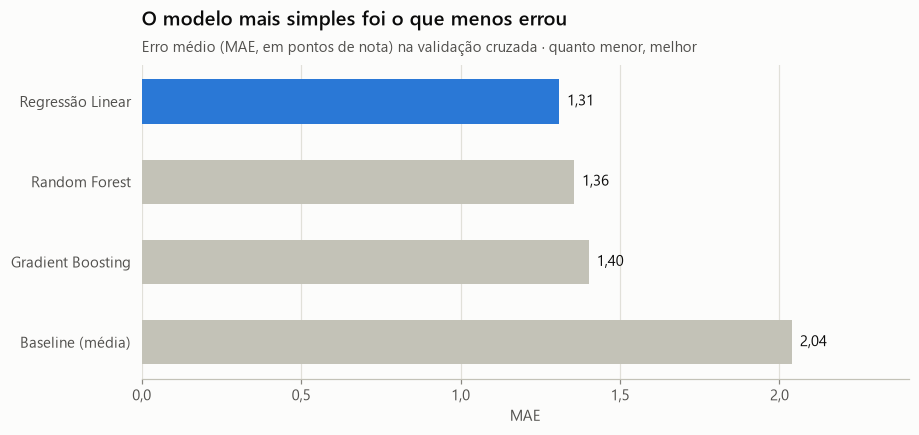

Modelo escolhido: Regressão Linear


In [6]:
chosen_model_name = regression_cv.loc[0, "modelo"]
fig = viz.plot_model_comparison(
    regression_cv,
    metric="MAE",
    title="O modelo mais simples foi o que menos errou",
    subtitle="Erro médio (MAE, em pontos de nota) na validação cruzada · quanto menor, melhor",
    chosen=chosen_model_name,
)
viz.save_figure(fig, "12_modelo_comparacao.png")
plt.show()
print("Modelo escolhido:", chosen_model_name)

**A Regressão Linear teve o menor erro (1,31 ponto), e os modelos mais complexos não melhoraram
o resultado.** Isso confirma o que a EDA mostrou: os efeitos de atraso, reclamações, contatos e
resolução **se somam** de forma quase linear (cada dia de atraso tira mais ou menos a mesma coisa).
Quando o modelo simples é tão bom quanto o complexo, ele é a melhor escolha: é mais fácil de
explicar, auditar e manter.

Para comparar as duas estratégias, rodamos a mesma comparação com **classificadores**
(alvo: o cliente será detrator?). A métrica é o **ROC-AUC**, que mede quão bem o modelo ordena os
clientes do mais arriscado ao menos arriscado (0,5 = sorteio; 1,0 = ordenação perfeita).

In [7]:
classification_cv = modeling.compare_classifiers(X_train, y_train)
classification_cv

,modelo,ROC_AUC,PR_AUC,Acuracia_balanceada
0,Regressão Logística,0.895,0.979,0.676
1,Random Forest,0.885,0.975,0.631
2,Gradient Boosting,0.869,0.972,0.669
3,Baseline (proporção),0.500,0.843,0.500


## 8. Avaliação no conjunto de teste

O modelo escolhido é treinado com todo o treino e avaliado **uma única vez** no teste.

In [8]:
model = modeling.make_pipeline(LinearRegression()).fit(X_train, y_train)
y_pred = modeling.predict_nps(model, X_test)

baseline = modeling.make_pipeline(modeling.regression_candidates()["Baseline (média)"]).fit(X_train, y_train)
test_metrics = pd.DataFrame(
    {
        "Regressão Linear": modeling.regression_metrics(y_test, y_pred),
        "Baseline (média)": modeling.regression_metrics(y_test, modeling.predict_nps(baseline, X_test)),
    }
).T
error_reduction = 1 - test_metrics.loc["Regressão Linear", "MAE"] / test_metrics.loc["Baseline (média)", "MAE"]
print(f"Redução do erro em relação ao baseline: {error_reduction:.0%}")
test_metrics

Redução do erro em relação ao baseline: 34%


,MAE,RMSE,R2
Regressão Linear,1.386,1.780,0.511
Baseline (média),2.105,2.550,-0.005


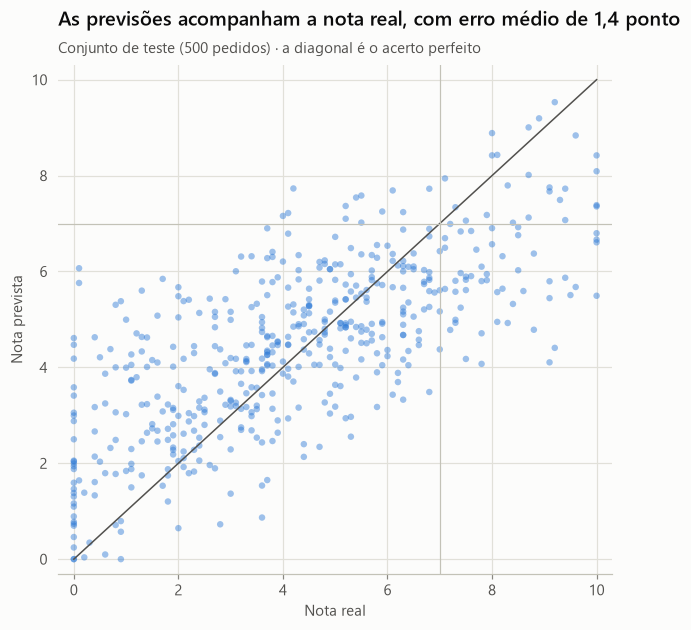

In [9]:
fig = viz.plot_predicted_vs_actual(
    y_test, y_pred,
    title="As previsões acompanham a nota real, com erro médio de 1,4 ponto",
    subtitle="Conjunto de teste (500 pedidos) · a diagonal é o acerto perfeito",
)
viz.save_figure(fig, "13_modelo_previsto_vs_real.png")
plt.show()

**Leitura:** o modelo erra, em média, **1,4 ponto** na nota (contra 2,1 do baseline), um erro
**34% menor**. O R² de 0,51 indica que o modelo explica **cerca de metade** da variação das notas.
A outra metade vem de coisas que não estão na base: qualidade do produto, expectativa do cliente,
humor no dia da pesquisa.

### 8.1 A regressão também separa detratores?

Para validar a escolha da estratégia, comparamos no mesmo teste a capacidade de **ordenar
detratores** da nota prevista pela regressão com a do melhor classificador.

ROC-AUC usando a nota prevista pela regressão: 0.868
ROC-AUC do melhor classificador (Regressão Logística): 0.869


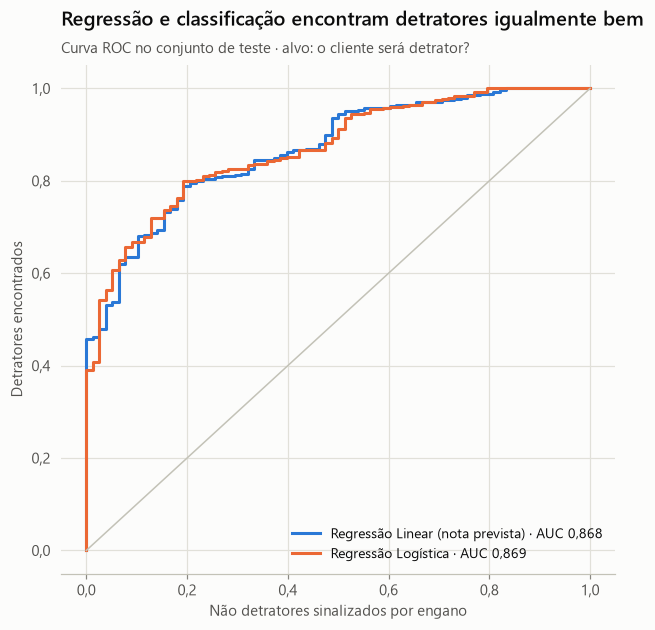

In [10]:
is_detractor_test = (y_test < config.DETRACTOR_LIMIT).astype(int)
best_classifier_name = classification_cv.loc[0, "modelo"]
classifier = modeling.make_pipeline(modeling.classification_candidates()[best_classifier_name]).fit(
    X_train, (y_train < config.DETRACTOR_LIMIT).astype(int)
)
classifier_probability = classifier.predict_proba(X_test)[:, 1]

regression_ranking = modeling.detractor_ranking_metrics(y_test, y_pred)
classifier_auc = roc_auc_score(is_detractor_test, classifier_probability)
print(f"ROC-AUC usando a nota prevista pela regressão: {regression_ranking['ROC_AUC']:.3f}")
print(f"ROC-AUC do melhor classificador ({best_classifier_name}): {classifier_auc:.3f}")

fig, ax = plt.subplots(figsize=(6.5, 6))
for label, score, color in [
    (f"Regressão Linear (nota prevista) · AUC {viz.fmt_number(regression_ranking['ROC_AUC'], 3)}", -y_pred, viz.HIGHLIGHT),
    (f"{best_classifier_name} · AUC {viz.fmt_number(classifier_auc, 3)}", classifier_probability, "#eb6834"),
]:
    false_positive_rate, true_positive_rate, _ = roc_curve(is_detractor_test, score)
    ax.plot(false_positive_rate, true_positive_rate, linewidth=2, color=color, label=label)
ax.plot([0, 1], [0, 1], color=viz.AXIS, linewidth=1)
ax.xaxis.set_major_formatter(viz.decimal_axis)
ax.yaxis.set_major_formatter(viz.decimal_axis)
ax.set_xlabel("Não detratores sinalizados por engano")
ax.set_ylabel("Detratores encontrados")
ax.grid(axis="x")
ax.legend(loc="lower right", fontsize=9)
viz.set_titles(ax, "Regressão e classificação encontram detratores igualmente bem",
               "Curva ROC no conjunto de teste · alvo: o cliente será detrator?")
viz.save_figure(fig, "14_modelo_curva_roc.png")
plt.show()

As duas curvas praticamente se sobrepõem (AUC 0,868 contra 0,869). **A regressão entrega tudo o
que a classificação entregaria e ainda dá a nota.** Isso confirma a estratégia escolhida no item 2.

### 8.2 Faixas de risco

A nota prevista "puxa para a média": o modelo raramente prevê 9 ou 10, porque a base tem poucos
promotores e eles dependem em parte de fatores que não estão nos dados. Por isso **não usamos a
categoria prevista diretamente**: veja abaixo como ela quase nunca acerta promotores.

In [11]:
predicted_category = data_prep.classify_nps(pd.Series(y_pred, index=y_test.index))
pd.crosstab(test_df["nps_category"], predicted_category, rownames=["categoria real"],
            colnames=["categoria prevista"], margins=True, margins_name="total")

categoria prevista,detrator,neutro,promotor,total
categoria real,,,,
detrator,410,12,0,422
neutro,43,11,2,56
promotor,11,10,1,22
total,464,33,3,500


Em vez disso, a nota prevista é usada para **ordenar** os pedidos em faixas de risco. A tabela abaixo
mostra, no teste, como os clientes de cada faixa **realmente** avaliaram:

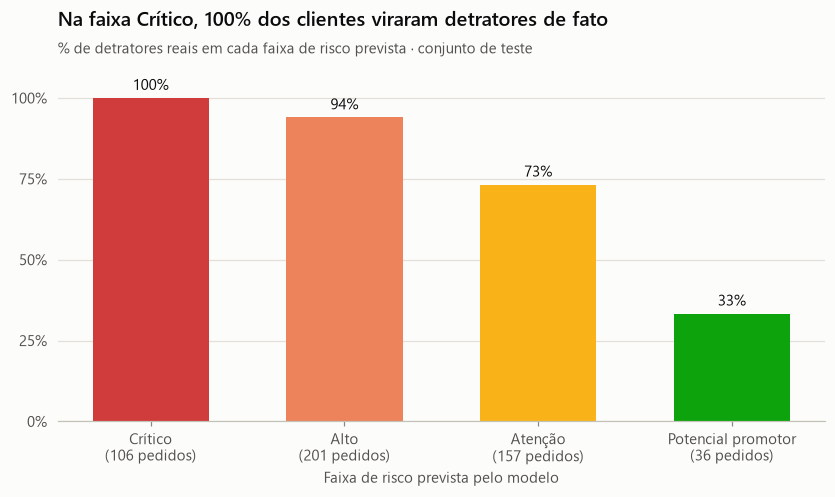

,pedidos,nota_real_media,pct_detratores_reais,pct_promotores_reais,pct_pedidos
faixa_risco,,,,,
Crítico,106,1.700,100.000,0.000,21.200
Alto,201,3.900,94.000,1.000,40.200
Atenção,157,5.600,73.200,5.700,31.400
Potencial promotor,36,7.600,33.300,30.600,7.200


In [12]:
tier_table = modeling.risk_tier_table(y_test, y_pred)
fig = viz.plot_risk_tiers(
    tier_table,
    title="Na faixa Crítico, 100% dos clientes viraram detratores de fato",
    subtitle="% de detratores reais em cada faixa de risco prevista · conjunto de teste",
)
viz.save_figure(fig, "15_modelo_faixas_risco.png")
plt.show()
tier_table

**Leitura:** as faixas funcionam como um semáforo confiável.

- **Crítico** (nota prevista abaixo de 3): 21% dos pedidos; **100% viraram detratores** de fato.
  Aqui a ação proativa tem certeza de alvo.
- **Alto** (3 a 5): 40% dos pedidos; 94% detratores.
- **Atenção** (5 a 7): 31% dos pedidos; 73% detratores.
- **Potencial promotor** (7 ou mais): 7% dos pedidos; **31% viraram promotores**, sete vezes a
  taxa da base (4,4%). É o grupo certo para pedir avaliação ou indicação.

## 9. O que o modelo aprendeu

Como o modelo é linear, cada variável tem um **peso** que pode ser lido em linguagem de negócio:
"quanto a nota muda quando esta variável aumenta 1 unidade, mantendo o resto igual". A tabela abaixo
usa o `statsmodels`, que mostra o intervalo de confiança e o p-valor de cada peso. Os pesos são os
mesmos do modelo do scikit-learn.

In [13]:
formula = "nps_score ~ " + " + ".join(config.NUMERIC_FEATURES) + " + C(customer_region)"
ols = smf.ols(formula, data=train_df).fit()

coefficients = pd.DataFrame(
    {
        "peso (pontos por unidade)": ols.params,
        "IC 95% inferior": ols.conf_int()[0],
        "IC 95% superior": ols.conf_int()[1],
        "p_valor": ols.pvalues.round(4),
    }
).drop(index="Intercept")
coefficients.index = [config.FEATURE_LABELS.get(name, name) for name in coefficients.index]
print(f"R² no treino: {ols.rsquared:.3f}")
coefficients.reindex(coefficients["peso (pontos por unidade)"].abs().sort_values(ascending=False).index)

R² no treino: 0.573


,peso (pontos por unidade),IC 95% inferior,IC 95% superior,p_valor
Dias de atraso,-0.937,-0.990,-0.884,0.000
Reclamações,-0.374,-0.439,-0.308,0.000
Contatos com o atendimento,-0.353,-0.446,-0.260,0.000
Tempo de resolução (dias),-0.140,-0.161,-0.119,0.000
C(customer_region)[T.Sudeste],0.125,-0.103,0.353,0.282
C(customer_region)[T.Sul],0.110,-0.118,0.338,0.345
C(customer_region)[T.Nordeste],0.109,-0.123,0.341,0.357
Tentativas de entrega,0.101,0.013,0.190,0.025
C(customer_region)[T.Norte],0.049,-0.182,0.280,0.677
Quantidade de itens,0.012,-0.030,0.055,0.570


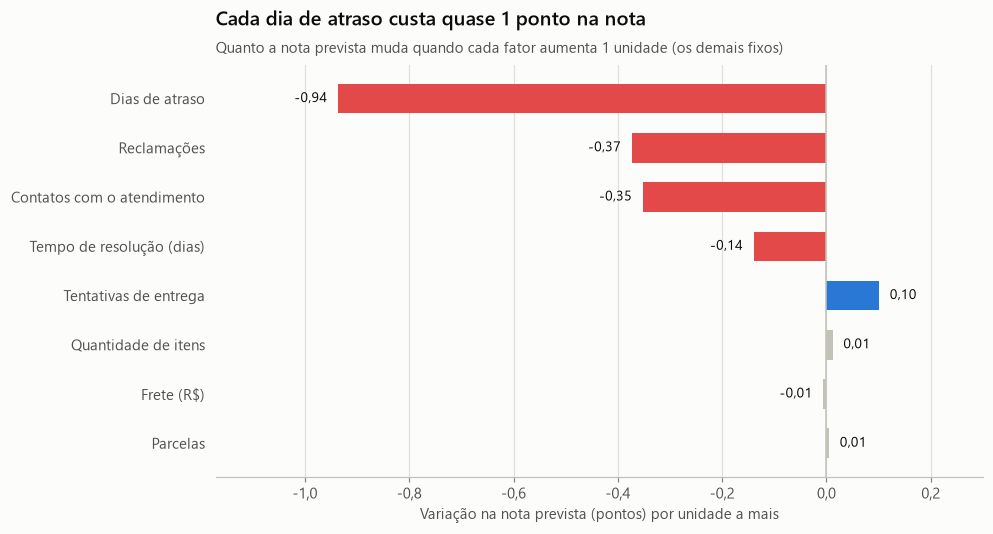

In [14]:
impacts = modeling.unit_impacts(model)
fig = viz.plot_unit_impacts(
    impacts,
    title="Cada dia de atraso custa quase 1 ponto na nota",
    subtitle="Quanto a nota prevista muda quando cada fator aumenta 1 unidade (os demais fixos)",
    top=8,
)
viz.save_figure(fig, "16_modelo_impacto_fatores.png")
plt.show()

**Leitura:**

| A cada... | a nota cai |
|---|---|
| 1 dia de atraso | **0,94 ponto** |
| 1 reclamação a mais | 0,37 ponto |
| 1 contato a mais com o atendimento | 0,35 ponto |
| 1 dia a mais para resolver o problema | 0,14 ponto |

Valor do pedido, frete e tentativas de entrega aparecem com p-valor abaixo de 0,05, mas o efeito
prático é desprezível: R\$ 100 a mais no pedido mudam a nota em 0,1 ponto. É o mesmo alerta da
EDA: **significância estatística não é relevância para o negócio**.

Um pedido sem atraso, sem reclamação, sem contato e com resolução imediata teria nota prevista de
**9,3**, ou seja, de promotor (cálculo abaixo). A nota da empresa é baixa porque quase nenhum
pedido chega perto desse cenário: **só 1 dos 2.500 pedidos** teve os quatro fatores zerados.

In [15]:
# "Pedido perfeito": demais variáveis na mediana da base, os quatro fatores operacionais zerados
perfect_order = X_train.median(numeric_only=True).to_frame().T
perfect_order["customer_region"] = X_train["customer_region"].mode()[0]
perfect_order[config.OPERATIONAL_DRIVERS] = 0
print(f"Nota prevista para o pedido perfeito: {modeling.predict_nps(model, perfect_order[config.MODEL_FEATURES])[0]:.1f}")
print(f"Pedidos da base com os quatro fatores zerados: {(df[config.OPERATIONAL_DRIVERS] == 0).all(axis=1).sum()}")

Nota prevista para o pedido perfeito: 9.3
Pedidos da base com os quatro fatores zerados: 1


In [16]:
# Duas checagens de robustez:
# 1) Multicolinearidade: reclamações e contatos andam juntos (correlação 0,74). O VIF mede se isso
#    deixa os pesos instáveis. Abaixo de 5 é considerado seguro.
vif_data = train_df[config.OPERATIONAL_DRIVERS].assign(const=1.0)
vif = pd.Series(
    [variance_inflation_factor(vif_data.to_numpy(), i) for i in range(len(config.OPERATIONAL_DRIVERS))],
    index=[config.FEATURE_LABELS[c] for c in config.OPERATIONAL_DRIVERS],
    name="VIF",
)
print(vif.round(2).to_string(), "\n")

# 2) Importância por permutação (vale para qualquer modelo): embaralha uma variável por vez no teste
#    e mede quanto o erro aumenta. Quanto maior o aumento, mais o modelo depende daquela variável.
permutation = permutation_importance(
    model, X_test, y_test, scoring="neg_mean_absolute_error", n_repeats=20, random_state=config.RANDOM_STATE
)
pd.Series(permutation.importances_mean, index=[config.FEATURE_LABELS[c] for c in config.MODEL_FEATURES],
          name="aumento do erro (pontos)").sort_values(ascending=False).head(6).round(3)

Dias de atraso               1.120
Reclamações                  2.630
Contatos com o atendimento   2.520
Tempo de resolução (dias)    1.000 



Dias de atraso               0.805
Reclamações                  0.177
Tempo de resolução (dias)    0.126
Contatos com o atendimento   0.061
Região                       0.004
Tentativas de entrega        0.003
Name: aumento do erro (pontos), dtype: float64

Os VIFs ficam entre 1,0 e 2,6 (seguro). A importância por permutação confirma a hierarquia: sem a
informação de **atraso**, o erro do modelo sobe 0,8 ponto, muito mais do que qualquer outra variável.

**Versão enxuta:** e se o modelo usasse só os quatro fatores operacionais?

In [17]:
lean_model = Pipeline([("scaler", StandardScaler()), ("model", LinearRegression())])
lean = cross_validate(lean_model, train_df[config.OPERATIONAL_DRIVERS], y_train, cv=folds, scoring=scoring)
print(f"Modelo completo ({len(config.MODEL_FEATURES)} variáveis): MAE {-honest['test_MAE'].mean():.3f} | R² {honest['test_R2'].mean():.3f}")
print(f"Modelo enxuto  (4 variáveis):  MAE {-lean['test_MAE'].mean():.3f} | R² {lean['test_R2'].mean():.3f}")

Modelo completo (14 variáveis): MAE 1.309 | R² 0.565
Modelo enxuto  (4 variáveis):  MAE 1.309 | R² 0.564


O resultado é o mesmo. Para colocar em produção, **a versão com 4 variáveis exige menos
integrações de dados** (só logística e atendimento) e é mais fácil de explicar. Mantivemos o
modelo completo como oficial para que o pipeline continue funcionando caso, com dados reais, o
perfil do cliente passe a ter peso.

## 10. Simulação de cenários: quanto vale cada melhoria?

Usamos o modelo para responder perguntas do tipo "e se...?". Alteramos uma variável em todos os
pedidos da base e comparamos a **nota média prevista** com a atual.

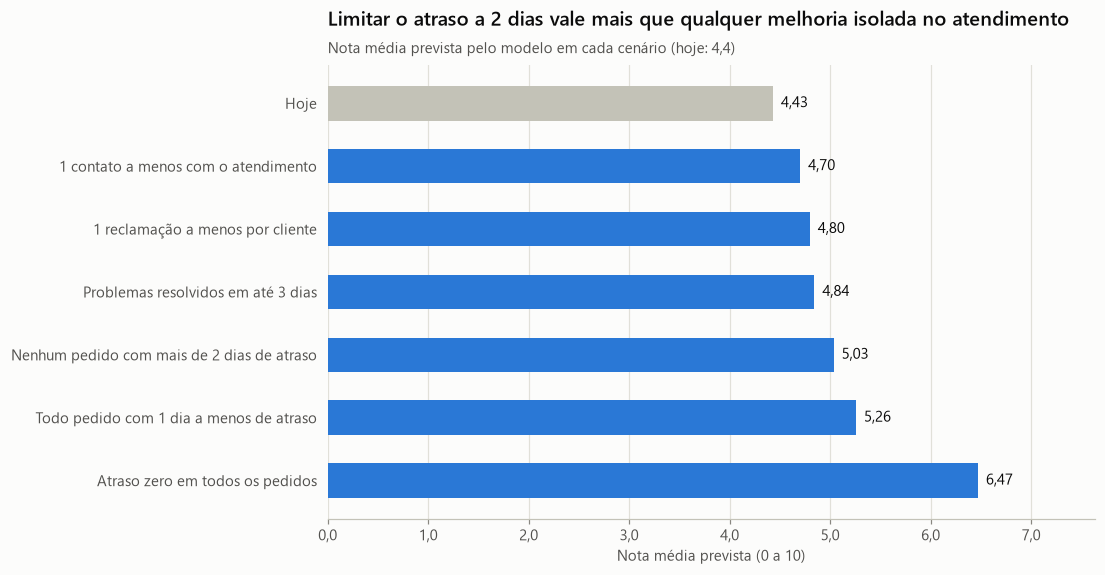

Hoje                                         4.430
Nenhum pedido com mais de 2 dias de atraso   5.030
Todo pedido com 1 dia a menos de atraso      5.260
Problemas resolvidos em até 3 dias           4.840
1 reclamação a menos por cliente             4.800
1 contato a menos com o atendimento          4.700
Atraso zero em todos os pedidos              6.470
Name: nota média prevista, dtype: float64

In [18]:
X_all, _ = modeling.get_features_and_target(df)
current_score = modeling.predict_nps(model, X_all).mean()


def simulate(change) -> float:
    """Aplica uma mudança nas variáveis e devolve a nota média prevista."""
    scenario = X_all.copy()
    change(scenario)
    return modeling.predict_nps(model, scenario).mean()


scenarios = pd.Series(
    {
        "Hoje": current_score,
        "Nenhum pedido com mais de 2 dias de atraso": simulate(
            lambda X: X.__setitem__("delivery_delay_days", X["delivery_delay_days"].clip(upper=2))),
        "Todo pedido com 1 dia a menos de atraso": simulate(
            lambda X: X.__setitem__("delivery_delay_days", (X["delivery_delay_days"] - 1).clip(lower=0))),
        "Problemas resolvidos em até 3 dias": simulate(
            lambda X: X.__setitem__("resolution_time_days", X["resolution_time_days"].clip(upper=3))),
        "1 reclamação a menos por cliente": simulate(
            lambda X: X.__setitem__("complaints_count", (X["complaints_count"] - 1).clip(lower=0))),
        "1 contato a menos com o atendimento": simulate(
            lambda X: X.__setitem__("customer_service_contacts", (X["customer_service_contacts"] - 1).clip(lower=0))),
        "Atraso zero em todos os pedidos": simulate(lambda X: X.__setitem__("delivery_delay_days", 0)),
    },
    name="nota média prevista",
)

fig = viz.plot_ranked_bars(
    scenarios.sort_values(),
    title="Limitar o atraso a 2 dias vale mais que qualquer melhoria isolada no atendimento",
    subtitle="Nota média prevista pelo modelo em cada cenário (hoje: 4,4)",
    xlabel="Nota média prevista (0 a 10)",
    highlight=[name for name in scenarios.index if name != "Hoje"],
)
viz.save_figure(fig, "17_simulacao_cenarios.png")
plt.show()
scenarios.round(2)

**Leitura:**

- **Garantir que nenhum pedido passe de 2 dias de atraso** leva a nota média de 4,4 para 5,0
  (+0,6), mais do que qualquer melhoria isolada no atendimento.
- **Reduzir 1 dia de atraso em todos os pedidos** vale +0,8.
- Cada melhoria de atendimento vale entre +0,3 e +0,4. Seria preciso fazer as três ao mesmo tempo
  para superar o efeito de limitar o atraso a 2 dias.
- **Atraso zero** levaria a nota média para 6,5.

*Cuidado:* o modelo aprendeu **associações**, não causas comprovadas. Os números servem para
**priorizar** investimentos; o ganho real precisa ser confirmado com um teste controlado (item 11).

## 11. Como a empresa usaria o modelo na prática

**Fluxo proposto:**

```
pedido entregue (ou atraso detectado)
   -> python -m src.predict calcula a nota prevista
   -> faixa de risco + fator que mais derruba a nota + área responsável
   -> fila de ação por área (Logística / Atendimento)
   -> pesquisa de NPS enviada normalmente
   -> previsão x nota real comparadas todo mês (monitoramento)
   -> modelo re-treinado quando o erro subir
```

| Faixa | Nota prevista | Ação recomendada |
|---|---|---|
| **Crítico** | abaixo de 3 | Contato proativo antes da pesquisa, pedido de desculpas e compensação (cupom ou frete grátis); chamado aberto vai para a fila prioritária |
| **Alto** | 3 a 5 | Avisar o cliente sobre o status da entrega antes que ele pergunte e acompanhar o chamado até o fim |
| **Atenção** | 5 a 7 | Monitorar; mensagem de acompanhamento após a entrega |
| **Potencial promotor** | 7 ou mais | Enviar a pesquisa no melhor momento e convidar para avaliação ou programa de indicação |

Exemplo da saída para os pedidos do teste (os 8 mais críticos):

In [19]:
scored_test = score_orders(test_df, model)
scored_test[["order_id", "delivery_delay_days", "complaints_count", "customer_service_contacts",
             "predicted_nps", "risk_tier", "main_driver", "driver_owner"]].head(8)

,order_id,delivery_delay_days,complaints_count,customer_service_contacts,predicted_nps,risk_tier,main_driver,driver_owner
0,52035,6,6,3,0.000,Crítico,Dias de atraso,Logística
1,50462,5,10,6,0.000,Crítico,Dias de atraso,Logística
2,52138,7,5,1,0.000,Crítico,Dias de atraso,Logística
3,52051,6,5,2,0.000,Crítico,Dias de atraso,Logística
4,52073,5,6,4,0.100,Crítico,Dias de atraso,Logística
5,51484,4,7,5,0.200,Crítico,Dias de atraso,Logística
6,51932,7,4,1,0.300,Crítico,Dias de atraso,Logística
7,51143,6,4,2,0.500,Crítico,Dias de atraso,Logística


In [20]:
at_risk = scored_test[scored_test["risk_tier"].isin(["Crítico", "Alto"])]
at_risk.groupby(["driver_owner", "main_driver"]).size().rename("pedidos em risco Crítico ou Alto").sort_values(ascending=False)

driver_owner           main_driver              
Logística              Dias de atraso               241
Atendimento / Produto  Reclamações                   64
Atendimento            Tempo de resolução (dias)      2
Name: pedidos em risco Crítico ou Alto, dtype: int64

**Como medir se está funcionando:**

- **Teste A/B:** nos pedidos de risco Crítico, sortear um grupo que recebe a ação proativa e um
  grupo de controle que não recebe. A diferença de NPS entre os dois é o **efeito real** da ação,
  que é o que justifica o custo da compensação.
- **Monitoramento mensal:** erro médio (MAE) da previsão contra a nota real, taxa de detratores por
  faixa de risco e mudança no perfil dos dados (ex.: aumento do atraso médio).
- **Uso antecipado:** como o atraso é o fator mais forte, o modelo pode rodar **no momento em que o
  atraso é detectado** (prazo estourado), antes mesmo da entrega, com a previsão sendo atualizada a
  cada novo evento.

## 12. Limitações e riscos

**Sobre os dados**

- **Sinais de base simulada:** as variáveis de entrada praticamente não se correlacionam entre si e
  várias têm distribuição uniforme (prazo, parcelas, tempo de resolução). As relações encontradas
  devem ser **revalidadas com dados reais** antes de qualquer decisão de investimento.
- **Um pedido por cliente e nenhuma data:** não há histórico do cliente nem como validar o modelo ao
  longo do tempo (sazonalidade, Black Friday, mudanças de transportadora).
- **16% de linhas com inconsistências** e dúvida sobre o que `complaints_count` conta.
- **Só quem respondeu a pesquisa está na base:** clientes que não respondem podem ter outro perfil.

**Sobre o modelo**

- Explica **cerca de metade** da variação da nota (R² 0,51); a outra metade depende de fatores fora
  da base.
- **Identifica mal os promotores:** a previsão "puxa para a média". Por isso o uso recomendado é por
  faixas de risco, não pela categoria prevista.
- **Associação não é causa:** os ganhos da simulação precisam ser confirmados com teste A/B.

**Sobre o uso**

- **Risco ético e de métrica:** o modelo **não pode** ser usado para deixar de enviar a pesquisa a
  quem tem risco de ser detrator. Isso inflaria o NPS sem melhorar nada e destruiria o valor do
  indicador.
- **Compensação vira expectativa:** se todo atraso gerar cupom, o cupom passa a ser esperado. A
  ação proativa precisa de regras e de orçamento definidos.
- **Re-treino:** se a operação melhorar (menos atrasos), o padrão dos dados muda e o modelo precisa
  ser re-treinado.

## Gerando os artefatos oficiais

A célula abaixo roda o mesmo pipeline do script `python -m src.train_model`, que re-treina o
modelo escolhido com 100% da base e grava `models/nps_regressor.joblib` e `models/metrics.json`.
As métricas de teste devem ser idênticas às calculadas acima. Os pesos do modelo final mudam um
pouco (ex.: atraso -0,95 em vez de -0,94), porque ele passa a ver também os 500 pedidos do teste.

In [21]:
from src.train_model import run_training

results = run_training(save=True)
print("Modelo escolhido:", results["modelo_escolhido"])
print("Teste:", results["teste_modelo_escolhido"])
print("Ordenação de detratores:", results["teste_ordenacao_detratores"])
print("Arquivos gravados:", config.MODEL_PATH.relative_to(config.PROJECT_ROOT), "e",
      config.METRICS_PATH.relative_to(config.PROJECT_ROOT))

Modelo escolhido: Regressão Linear
Teste: {'MAE': 1.386, 'RMSE': 1.78, 'R2': 0.511}
Ordenação de detratores: {'ROC_AUC': 0.868, 'PR_AUC': 0.973}
Arquivos gravados: models\nps_regressor.joblib e models\metrics.json
